In [2]:
# Importing the required libraries. 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier 
import xgboost as xgb
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, f1_score, accuracy_score

In [3]:
# Importing the dataset. 

spam_data = pd.read_csv(r"D:\AI_ML_DS Course_IIT Guwahati (Sept 2025-June 2026)\Internship Projects\04_Spam Prediction\data\spam_detection_dataset.csv")
spam_data

,num_links,num_words,has_offer,sender_score,all_caps,is_spam
0,3,98,1,0.718607,0,0
1,0,170,0,0.698901,1,0
2,0,38,0,0.620466,0,0
3,0,116,0,0.701755,0,0
4,3,89,1,0.583621,1,1
...,...,...,...,...,...,...
19995,1,22,1,0.614551,0,0
19996,3,154,0,1.000000,1,1
19997,4,109,0,0.935848,1,0
19998,2,197,0,0.481772,0,0


In [4]:
# Viewing the first 5 rows of the dataset.

spam_data.head()

,num_links,num_words,has_offer,sender_score,all_caps,is_spam
0,3,98,1,0.718607,0,0
1,0,170,0,0.698901,1,0
2,0,38,0,0.620466,0,0
3,0,116,0,0.701755,0,0
4,3,89,1,0.583621,1,1


In [5]:
# Viewing the last 5 rows of the dataset.

spam_data.tail()

,num_links,num_words,has_offer,sender_score,all_caps,is_spam
19995,1,22,1,0.614551,0,0
19996,3,154,0,1.000000,1,1
19997,4,109,0,0.935848,1,0
19998,2,197,0,0.481772,0,0
19999,0,116,0,0.566640,0,0


In [6]:
# Viewing the shape of the dataset.

spam_data.shape

(20000, 6)

In [7]:
# Viewing the size of the dataset. 

spam_data.size

120000

In [8]:
# Checking the overview of the dataset. 

spam_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   num_links     20000 non-null  int64  
 1   num_words     20000 non-null  int64  
 2   has_offer     20000 non-null  int64  
 3   sender_score  20000 non-null  float64
 4   all_caps      20000 non-null  int64  
 5   is_spam       20000 non-null  int64  
dtypes: float64(1), int64(5)
memory usage: 937.6 KB


In [9]:
# Checking the descriptive statistics of the dataset.

spam_data.describe()

,num_links,num_words,has_offer,sender_score,all_caps,is_spam
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.00000
mean,1.497300,109.506150,0.302750,0.694248,0.097800,0.09175
std,1.220478,51.969579,0.459459,0.188312,0.297051,0.28868
min,0.000000,20.000000,0.000000,0.000000,0.000000,0.00000
25%,1.000000,64.000000,0.000000,0.567073,0.000000,0.00000
50%,1.000000,110.000000,0.000000,0.699740,0.000000,0.00000
75%,2.000000,154.000000,1.000000,0.834083,0.000000,0.00000
max,9.000000,199.000000,1.000000,1.000000,1.000000,1.00000


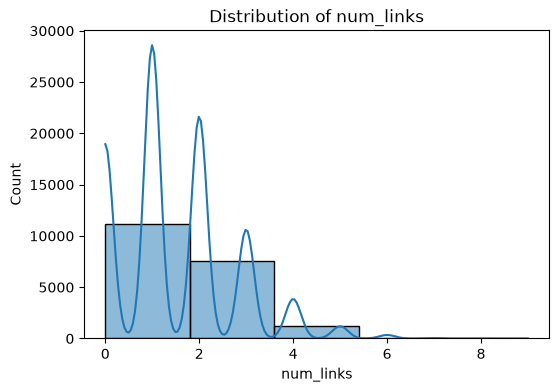

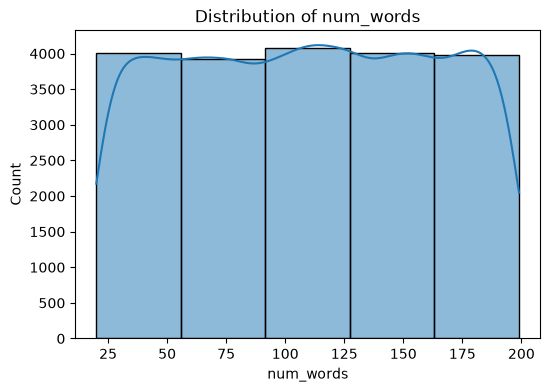

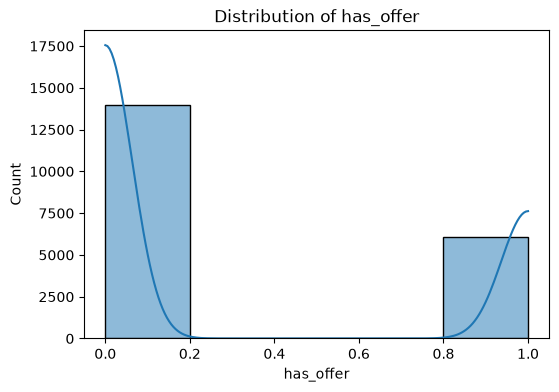

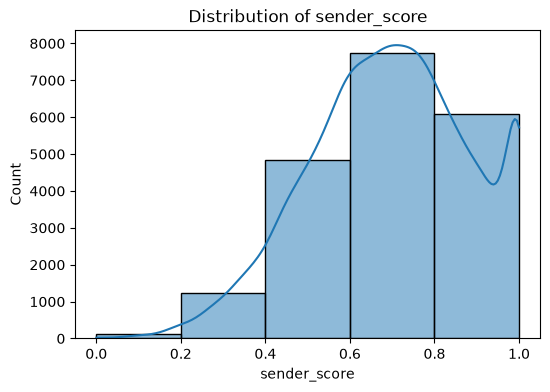

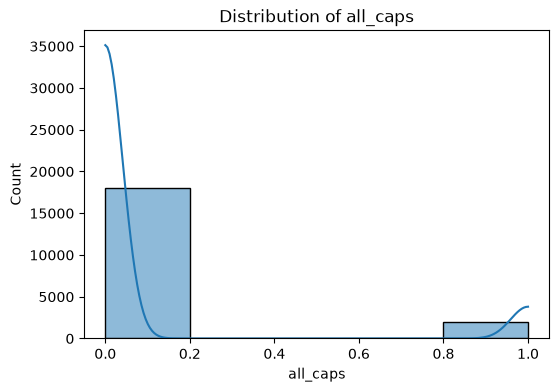

In [10]:
# Checking the distribution of numerical variables using histograms.

for col in spam_data.columns:
    if col != "is_spam":
        plt.figure(figsize = (6, 4))
        sns.histplot(spam_data[col], kde = True, bins = 5)
        plt.title(f"Distribution of {col}")
        plt.show()

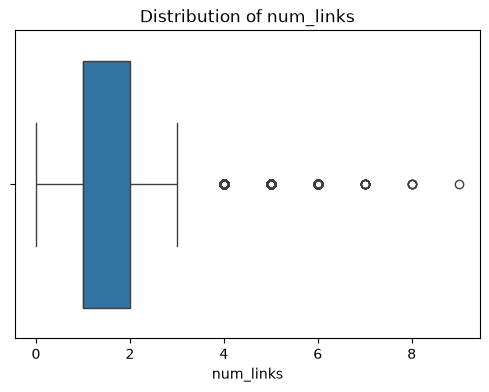

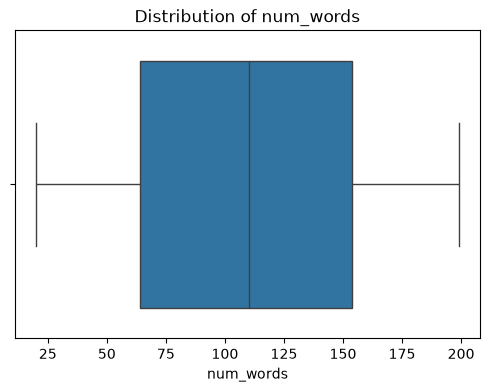

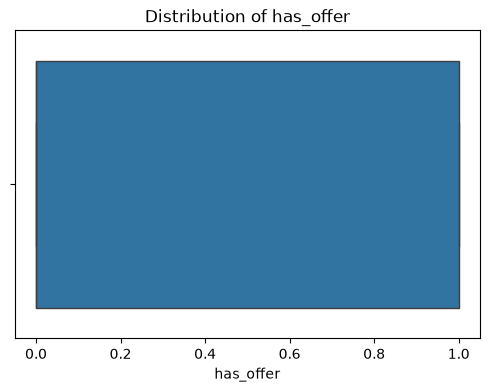

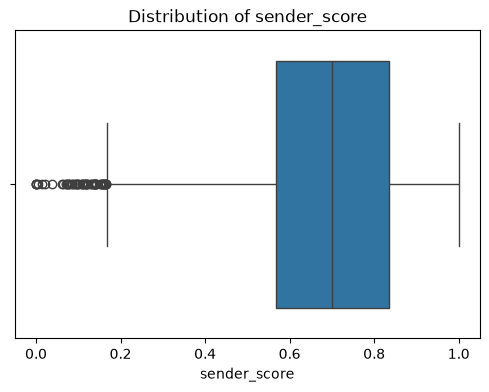

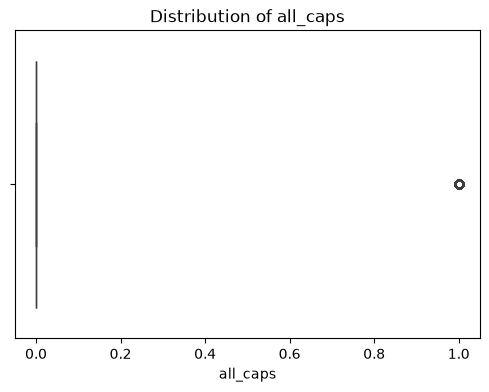

In [11]:
# Checking the distribution of numerical variables using boxplots.

for col in spam_data.columns:
    if col != "is_spam":
        plt.figure(figsize = (6, 4))
        sns.boxplot(x = spam_data[col], showfliers = True)
        plt.title(f"Distribution of {col}")
        plt.show()

In [12]:
# Checking the total number of missing values (NaN) in each column of the dataset. 

spam_data.isnull().sum()

num_links       0
num_words       0
has_offer       0
sender_score    0
all_caps        0
is_spam         0
dtype: int64

In [13]:
# Checking the total number of duplicate rows in the dataset.

spam_data.duplicated().sum()

np.int64(402)

In [14]:
# Dropping 402 duplicate rows from the dataset.

spam_data.drop_duplicates(subset = None, keep = "first", inplace = True)

In [15]:
# Checking the total number of outliers in each column of the dataset using the IQR method.

for col in spam_data.columns:
    if col != "is_spam":
        Q1 = spam_data[col].quantile(0.25)
        Q3 = spam_data[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR 
        upper_bound = Q3 + 1.5 * IQR

        outliers = spam_data[(spam_data[col] < lower_bound) | (spam_data[col] > upper_bound)]
        print(f"Total number of outliers in {col}: {outliers.shape[0]}")

Total number of outliers in num_links: 1274
Total number of outliers in num_words: 0
Total number of outliers in has_offer: 0
Total number of outliers in sender_score: 73
Total number of outliers in all_caps: 1947


In [16]:
# Checking the distribution of the target variable "is_spam".

spam_data["is_spam"].value_counts()

is_spam
0    17765
1     1833
Name: count, dtype: int64

##### From the output above, we can say that the target variable (is_spam) is imbalanced, with 0 (not spam/ham) being 90.65% (majority class), whereas 1 (spam) being 9.35% (minority class).  

In [17]:
# Checking the number of unique values in each column of the dataset.

spam_data.nunique()

num_links          10
num_words         180
has_offer           2
sender_score    18647
all_caps            2
is_spam             2
dtype: int64

In [18]:
# Splitting the dataset into features (X) and target variable (y).
# X

X = spam_data.drop("is_spam", axis = 1) # axis = 1 means we are dropping a column. 
X

,num_links,num_words,has_offer,sender_score,all_caps
0,3,98,1,0.718607,0
1,0,170,0,0.698901,1
2,0,38,0,0.620466,0
3,0,116,0,0.701755,0
4,3,89,1,0.583621,1
...,...,...,...,...,...
19995,1,22,1,0.614551,0
19996,3,154,0,1.000000,1
19997,4,109,0,0.935848,1
19998,2,197,0,0.481772,0


In [19]:
# y

y = spam_data["is_spam"]
y

0        0
1        0
2        0
3        0
4        1
        ..
19995    0
19996    1
19997    0
19998    0
19999    0
Name: is_spam, Length: 19598, dtype: int64

In [20]:
# Splitting the dataset into training and testing sets.

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y) # stratify = y because the target variable in the dataset is imbalanced. 
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((15678, 5), (3920, 5), (15678,), (3920,))

##### We will use Pipeline that automatically handles feature scaling, SMOTE, and building different ML models. 

In [21]:
# Importing Pipeline and SMOTE. 

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [22]:
# Creating LR, DT, RF, and XGB pipelines with scaling and SMOTE. 
# For LR

LR_pipeline = Pipeline([
    ("sc", StandardScaler()),
    ("smote", SMOTE(random_state = 42)),
    ("model", LogisticRegression(random_state = 42, max_iter = 1000))
])

# Tree-based models DO NOT require feature scaling, so we will NOT include StandardScaler in the pipelines for DT, RF, and XGB.
# For DT

DT_pipeline = Pipeline([
    ("smote", SMOTE(random_state = 42)),
    ("model", DecisionTreeClassifier(random_state = 42))
])

# For RF

RF_pipeline = Pipeline([
    ("smote", SMOTE(random_state = 42)),
    ("model", RandomForestClassifier(random_state = 42))
])

# For XGB

XGB_pipeline = Pipeline([
    ("smote", SMOTE(random_state = 42)),
    ("model", xgb.XGBClassifier(random_state = 42))
])

In [23]:
# Using StratifiedKFold (SKF) for cross-validation (CV) to maintain the distribution of the target variable in each fold.  

skf = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

In [ ]:
# CV ROC-AUC score for LR model. 

LR_CV_ROC_AUC = cross_val_score(LR_pipeline, X_train, y_train, cv = skf, scoring = "roc_auc") # Performs SKF CV and computes ROC-AUC score for each fold. 

# CV ROC-AUC score for DT model.

DT_CV_ROC_AUC = cross_val_score(DT_pipeline, X_train, y_train, cv = skf, scoring = "roc_auc")

# CV ROC-AUC score for RF model.

RF_CV_ROC_AUC = cross_val_score(RF_pipeline, X_train, y_train, cv = skf, scoring = "roc_auc")

# CV ROC-AUC score for XGB model.

XGB_CV_ROC_AUC = cross_val_score(XGB_pipeline, X_train, y_train, cv = skf, scoring = "roc_auc")

In [ ]:
# Now, we will fit the pipelines on the training set and evaluate them on the test set. 
# For LR

LR_pipeline.fit(X_train, y_train)
y_pred_LR = LR_pipeline.predict(X_test)

# For DT

DT_pipeline.fit(X_train, y_train)
y_pred_DT = DT_pipeline.predict(X_test)

# For RF

RF_pipeline.fit(X_train, y_train)
y_pred_RF = RF_pipeline.predict(X_test)

# For XGB

XGB_pipeline.fit(X_train, y_train)
y_pred_XGB = XGB_pipeline.predict(X_test)

In [ ]:
# Printing the mean CV ROC-AUC scores for all models.

print("Mean CV ROC-AUC score for LR: ", np.mean(LR_CV_ROC_AUC).round(4)) # LR
print("Mean CV ROC-AUC score for DT: ", np.mean(DT_CV_ROC_AUC).round(4)) # DT
print("Mean CV ROC-AUC score for RF: ", np.mean(RF_CV_ROC_AUC).round(4)) # RF
print("Mean CV ROC-AUC score for XGB: ", np.mean(XGB_CV_ROC_AUC).round(4)) # XGB

Mean CV ROC-AUC score for LR:  0.9478
Mean CV ROC-AUC score for DT:  0.8267
Mean CV ROC-AUC score for RF:  0.9467
Mean CV ROC-AUC score for XGB:  0.9484


In [ ]:
# Printing the classification report for each model.

print("Classification Report for LR:\n", classification_report(y_test, y_pred_LR)) # LR
print("Classification Report for DT:\n", classification_report(y_test, y_pred_DT)) # DT
print("Classification Report for RF:\n", classification_report(y_test, y_pred_RF)) # RF
print("Classification Report for XGB:\n", classification_report(y_test, y_pred_XGB)) # XGB

Classification Report for LR:
               precision    recall  f1-score   support

           0       0.99      0.86      0.92      3553
           1       0.40      0.90      0.55       367

    accuracy                           0.86      3920
   macro avg       0.69      0.88      0.73      3920
weighted avg       0.93      0.86      0.88      3920

Classification Report for DT:
               precision    recall  f1-score   support

           0       0.98      0.87      0.92      3553
           1       0.40      0.83      0.54       367

    accuracy                           0.87      3920
   macro avg       0.69      0.85      0.73      3920
weighted avg       0.93      0.87      0.89      3920

Classification Report for RF:
               precision    recall  f1-score   support

           0       0.99      0.89      0.94      3553
           1       0.45      0.87      0.60       367

    accuracy                           0.89      3920
   macro avg       0.72      0.88  

In [ ]:
# Printing the confusion matrix for each model. 

print("Confusion Matrix for LR:\n", confusion_matrix(y_test, y_pred_LR)) # LR
print("Confusion Matrix for DT:\n", confusion_matrix(y_test, y_pred_DT)) # DT
print("Confusion Matrix for RF:\n", confusion_matrix(y_test, y_pred_RF)) # RF
print("Confusion Matrix for XGB:\n", confusion_matrix(y_test, y_pred_XGB)) # XGB

Confusion Matrix for LR:
 [[3045  508]
 [  35  332]]
Confusion Matrix for DT:
 [[3092  461]
 [  61  306]]
Confusion Matrix for RF:
 [[3169  384]
 [  47  320]]
Confusion Matrix for XGB:
 [[3182  371]
 [  36  331]]


In [ ]:
# Creating metrics comparison table for all models.

results = pd.DataFrame({
    "Model": ["LR", "DT", "RF", "XGB"],
    "Mean CV ROC-AUC": [np.mean(LR_CV_ROC_AUC).round(4), np.mean(DT_CV_ROC_AUC).round(4), np.mean(RF_CV_ROC_AUC).round(4), np.mean(XGB_CV_ROC_AUC).round(4)],
    "Test ROC-AUC": [roc_auc_score(y_test, y_pred_LR), roc_auc_score(y_test, y_pred_DT), roc_auc_score(y_test, y_pred_RF), roc_auc_score(y_test, y_pred_XGB)],
    "Test F1 Score": [f1_score(y_test, y_pred_LR), f1_score(y_test, y_pred_DT), f1_score(y_test, y_pred_RF), f1_score(y_test, y_pred_XGB)]
})

print(results)

  Model  Mean CV ROC-AUC  Test ROC-AUC  Test F1 Score
0    LR           0.9478      0.880827       0.550124
1    DT           0.8267      0.852019       0.539683
2    RF           0.9467      0.881928       0.597572
3   XGB           0.9484      0.898744       0.619270


##### Among the four evaluated models, XGB demonstrated the strongest overall performance, achieving the highest mean CV ROC-AUC (0.9484), test ROC-AUC (0.8987), and test F1-score (0.6193). Therefore, we will tune the hyperparameters for the XGB model. 

In [ ]:
# Hyperparameter tuning for the XGB model using GridSearchCV.
# Defining the hyperparameter grid for the XGB model. 

param_grid_XGB = {
    "model__n_estimators": [100, 200, 300], # model__ means we are tuning the hyperparameters of the XGB model inside the XGB_pipeline. This is because XGB is inside the pipeline, under the name "model".
    "model__max_depth": [3, 5, 7],
    "model__learning_rate": [0.01, 0.1, 0.2],
    "model__subsample": [0.8, 1.0]
}

# Creating the GridSearchCV object. 

grid_search_XGB = GridSearchCV(estimator = XGB_pipeline, param_grid = param_grid_XGB, cv = skf, scoring = "f1", n_jobs = -1, verbose = 1)

# Performing the hyperparameter tuning using GridSearchCV for the XGB model. 

grid_search_XGB.fit(X_train, y_train)

# Getting the best hyperparameters for the XGB model.  

grid_search_XGB.best_params_

# Getting the best CV F1 score for the XGB model. 

grid_search_XGB.best_score_

# Storing the best-fitted XGB model. 

best_XGB_model = grid_search_XGB.best_estimator_ 

# Evaluating the tuned model on the test dataset. 

grid_search_XGB_tuned = best_XGB_model.predict(X_test)

# Checking the accuracy on the test dataset. 

print("Accuracy of the Tuned XGB Model on the Test Dataset:", accuracy_score(y_test, grid_search_XGB_tuned).round(4))  

Fitting 5 folds for each of 54 candidates, totalling 270 fits
Accuracy of the Tuned XGB Model on the Test Dataset: 0.9336734693877551


In [ ]:
# Saving the best-fitted XGB model and model columns. 

model_data = {
    "model": best_XGB_model,
    "columns": X_train.columns.tolist() 
}

joblib.dump(model_data, "XGB_Model.pkl")

In [ ]:
# Predicting the probabilities for the positive class. 

y_pred_proba_LR = LR_pipeline.predict_proba(X_test)[:, 1] # Gets the probability that an observation belongs to 2nd column, i.e., Class 1 (Spam). 
y_pred_proba_DT = DT_pipeline.predict_proba(X_test)[:, 1]
y_pred_proba_RF = RF_pipeline.predict_proba(X_test)[:, 1]
y_pred_proba_XGB = XGB_pipeline.predict_proba(X_test)[:, 1]

In [ ]:
# Computing ROC curve values. 

fpr_LR, tpr_LR, _= roc_curve(y_test, y_pred_proba_LR) # Computes FPR and TPR.
fpr_DT, tpr_DT, _= roc_curve(y_test, y_pred_proba_DT)
fpr_RF, tpr_RF, _= roc_curve(y_test, y_pred_proba_RF)
fpr_XGB, tpr_XGB, _= roc_curve(y_test, y_pred_proba_XGB)

In [ ]:
# Computing ROC-AUC scores. 

ROC_AUC_LR = roc_auc_score(y_test, y_pred_proba_LR) # Computes ROC-AUC scores. 
ROC_AUC_DT = roc_auc_score(y_test, y_pred_proba_DT)
ROC_AUC_RF = roc_auc_score(y_test, y_pred_proba_RF)
ROC_AUC_XGB = roc_auc_score(y_test, y_pred_proba_XGB)

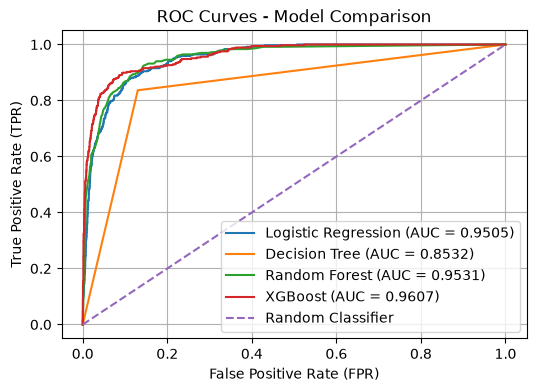

In [ ]:
# Plotting all ROC-AUC curves. 

plt.figure(figsize = (6, 4))

plt.plot(fpr_LR, tpr_LR, label = f"Logistic Regression (AUC = {ROC_AUC_LR:.4f})")
plt.plot(fpr_DT, tpr_DT, label = f"Decision Tree (AUC = {ROC_AUC_DT:.4f})")
plt.plot(fpr_RF, tpr_RF, label = f"Random Forest (AUC = {ROC_AUC_RF:.4f})")
plt.plot(fpr_XGB, tpr_XGB, label = f"XGBoost (AUC = {ROC_AUC_XGB:.4f})")

# Random classifier reference line.  

plt.plot([0, 1], [0, 1], linestyle = "--", label = "Random Classifier")

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curves - Model Comparison")
plt.legend(loc = "lower right")
plt.grid()
plt.show() 

In [ ]:
# Extracting the best model, XGB model. 

XGB_model = XGB_pipeline.named_steps["model"] # Extract the XGB model from the pipeline and store it in a variable called XGB_model.

In [ ]:
# Importing SHAP.

import shap

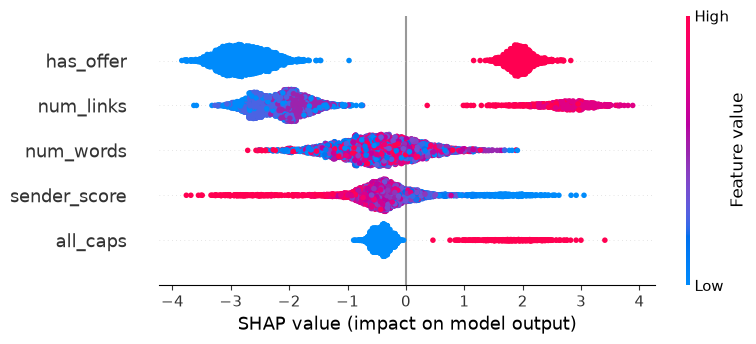

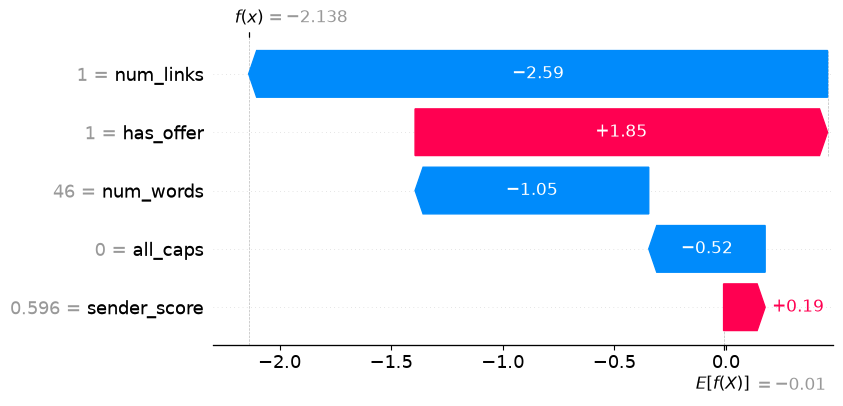

In [ ]:
# SHAP feature importance. 

explainer = shap.TreeExplainer(XGB_model) # XGB is a tree-based model. 

shap_values = explainer(X_test) 

shap.plots.beeswarm(shap_values)

shap.plots.waterfall(shap_values[0]) # Here, [0] means the first observation. This line of code means - Create a waterfall plot explaining why the model made its prediction for the 1st test observation. 

# Additional steps (optional)

In [ ]:
# To see the distribution of training and validation samples in each fold of SKF, we can use the following code:

for fold, (train_index, val_index) in enumerate(skf.split(X_train, y_train), 1):

    print(f"Fold {fold}:")
    print("Training samples:", len(train_index))
    print("Validation samples:", len(val_index))
    print()

Fold 1:
Training samples: 12542
Validation samples: 3136

Fold 2:
Training samples: 12542
Validation samples: 3136

Fold 3:
Training samples: 12542
Validation samples: 3136

Fold 4:
Training samples: 12543
Validation samples: 3135

Fold 5:
Training samples: 12543
Validation samples: 3135



In [ ]:
# To see the class distribution in every fold, we can use the following code: 

for fold, (train_index, val_index) in enumerate(skf.split(X_train, y_train), 1): 

    y_train_fold = y_train.iloc[train_index]
    y_val_fold = y_train.iloc[val_index]

    print(f"\nFold {fold}:")

    print("Training class distribution:")
    print(y_train_fold.value_counts())

    print("Validation class distribution:")
    print(y_val_fold.value_counts())


Fold 1:
Training class distribution:
is_spam
0    11369
1     1173
Name: count, dtype: int64
Validation class distribution:
is_spam
0    2843
1     293
Name: count, dtype: int64

Fold 2:
Training class distribution:
is_spam
0    11369
1     1173
Name: count, dtype: int64
Validation class distribution:
is_spam
0    2843
1     293
Name: count, dtype: int64

Fold 3:
Training class distribution:
is_spam
0    11370
1     1172
Name: count, dtype: int64
Validation class distribution:
is_spam
0    2842
1     294
Name: count, dtype: int64

Fold 4:
Training class distribution:
is_spam
0    11370
1     1173
Name: count, dtype: int64
Validation class distribution:
is_spam
0    2842
1     293
Name: count, dtype: int64

Fold 5:
Training class distribution:
is_spam
0    11370
1     1173
Name: count, dtype: int64
Validation class distribution:
is_spam
0    2842
1     293
Name: count, dtype: int64
